# Rabbits and foxes, with `solve_ivp`

**CHME 5137, Lecture 8, Tuesday October 6, 2026.** Started in class, finished for
homework.

*Revised for 2026 by Claude Code (Claude Opus 5.5) from the Lecture 3 notebook, and
checked by Prof. West. The problem is from Chapter 1 of H. Scott Fogler's
"Essentials of Chemical Reaction Engineering". The tasks are new.*

---

There are initially 400 rabbits and 200 foxes on a farm. (Or two cell types in a
96-well plate, if you prefer.) The populations obey

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

* Growth of rabbits, $k_1 = 0.015$ day$^{-1}$
* Death of rabbits being eaten by foxes, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$
* Growth of foxes after eating rabbits, $k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$
* Death of foxes, $k_4 = 0.04$ day$^{-1}$

In Lecture 3 you solved this with Euler's method. You found that the fox peaks,
which should all be the same height, crept upwards. At a step of 0.1 days (12,000
steps for 1200 days) they went 2816, 2854, 2893. At 0.005 days (240,000 steps) they
went 2804.5, 2806.4, 2808.2. Today: how well does a library do, and at what cost?

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Use the in-class notebook**, `solve-ivp-intro.ipynb`, for the syntax.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0

## 1. Solve it, and plot it

Write a function `dydt(t, y)` that returns $[dR/dt,\ dF/dt]$. Then call
`solve_ivp` with its **default** settings for 600 days.

Print `sol.success`, `sol.nfev` and `len(sol.t)`. Then plot both populations
against time, with axis labels and a legend.

True 242 32


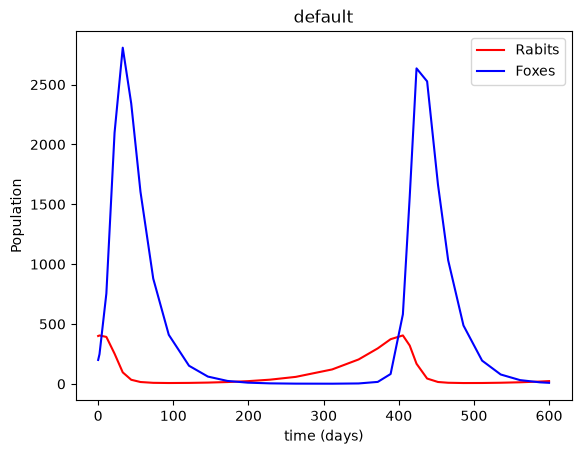

In [4]:
k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0
t_span = (0,600)

def dydt(t,y):
    R, F = y
    dRdt = k1*R-k2*R*F
    dFdt = k3*R*F-k4*F
    return [dRdt, dFdt]
# print(sol.y)

sol = solve_ivp(dydt, t_span, y0)
# sol = solve_ivp(dydt, t_span, y0, dense_output= True)
# sol = solve_ivp(dydt, t_span, y0, t_eval = np.linspace(0,600,400))
# sol = solve_ivp(dydt, t_span, y0, t_eval = np.linspace(0,600,400), dense_output= True)

print(sol.success, sol.nfev, len(sol.t))
plt.plot(sol.t, sol.y[0], label="Rabits", color = 'red', linestyle = '-')
plt.plot(sol.t, sol.y[1], label="Foxes", color ='blue', linestyle = '-')
plt.xlabel("time (days)")
plt.ylabel("Population")
plt.legend()
plt.title('default')
plt.show()

True 242 400


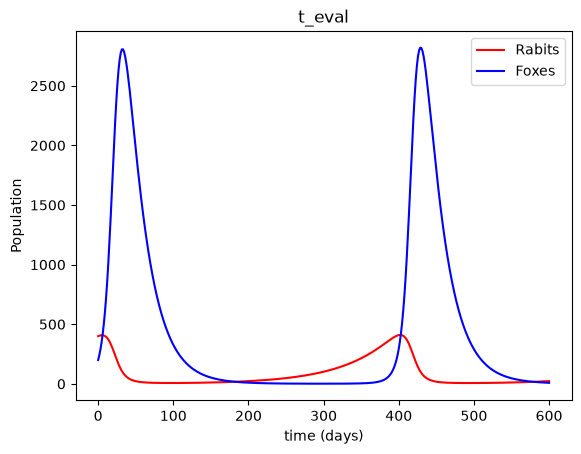

In [5]:
sol = solve_ivp(dydt, t_span, y0, t_eval = np.linspace(0,600,400))

print(sol.success, sol.nfev, len(sol.t))
plt.plot(sol.t, sol.y[0], label="Rabits", color = 'red', linestyle = '-')
plt.plot(sol.t, sol.y[1], label="Foxes", color ='blue', linestyle = '-')
plt.xlabel("time (days)")
plt.ylabel("Population")
plt.legend()
plt.title('t_eval')
plt.show()

True 242 32


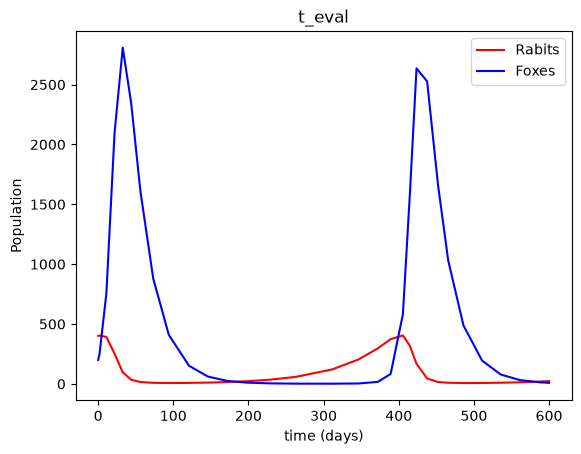

In [6]:
sol = solve_ivp(dydt, t_span, y0, dense_output= True)

print(sol.success, sol.nfev, len(sol.t))
plt.plot(sol.t, sol.y[0], label="Rabits", color = 'red', linestyle = '-')
plt.plot(sol.t, sol.y[1], label="Foxes", color ='blue', linestyle = '-')
plt.xlabel("time (days)")
plt.ylabel("Population")
plt.legend()
plt.title('t_eval')
plt.show()

Your plot is probably jagged. Why? Fix it in two ways: with `t_eval`, and with
`dense_output=True`. Does either one change `sol.nfev`?

*Answer:* nfev = [242,242,242,242] , len(sol.t) = [32,32,x,x] ... no neither changes the number of evaluations.  I was however able to smooth the curves by forcing in more data points with t_eval = np.linspace(0,600,70) 

## 2. The phase portrait

Solve to 1200 days, three full cycles, and plot foxes against rabbits. The exact
solution is a closed loop, traced over and over. Is yours?

True 440 500


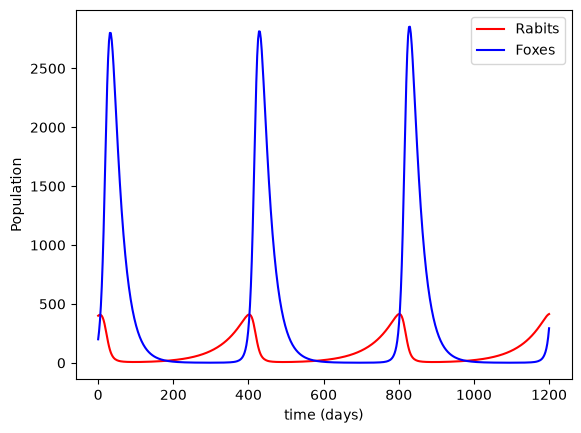

In [7]:
t_span = (0,1200)
# sol = solve_ivp(dydt, t_span, y0)
# sol = solve_ivp(dydt, t_span, y0, dense_output= True)
# sol = solve_ivp(dydt, t_span, y0, t_eval = np.linspace(0,1200,70))
sol = solve_ivp(dydt, t_span, y0, t_eval = np.linspace(0,1200,500), dense_output= True)

print(sol.success, sol.nfev, len(sol.t))
plt.plot(sol.t, sol.y[0], label="Rabits", color = 'red', linestyle = '-')
plt.plot(sol.t, sol.y[1], label="Foxes", color ='blue')
plt.xlabel("time (days)")
plt.ylabel("Population")
plt.legend()
plt.show()

*Answer:* My answer seems like a closed loop.  However, the fox curve is slightly changing each cycle

## 3. The height of each fox peak, using events

Searching `sol.y` for the largest value gives you the largest value **at the times
the solver happened to stop**, which won't be exactly at the peak. `solve_ivp` can
find the exact moment instead, with an *event*: a function `g(t, y)` that it
watches. It reports every time `g` passes through zero.

The foxes peak when $dF/dt$ changes from positive to negative. Since
$dF/dt = F(k_3 R - k_4)$ and $F > 0$, that happens when $k_3 R - k_4$ goes from
positive to negative. So:

```python
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4

fox_peak.direction = -1   # only count it when g is decreasing through zero

sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak)
sol.t_events[0]          # the times of the peaks
sol.y_events[0]          # the [R, F] values at each one
```

Print the time and height of each fox peak, with the default tolerances. Compare
with the Euler peaks above. How many function evaluations did it take, compared
with Euler's 12,000 or 240,000 steps?

In [10]:
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4

fox_peak.direction = -1   # only count it when g is decreasing through zero

sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak)
print(sol.t_events[0])          # the times of the peaks
print(sol.y_events[0])          # the [R, F] values at each one
print(sol.success, sol.nfev, len(sol.t))

[ 32.32034105 429.10196041 828.51594358]
[[ 100.         2808.62545428]
 [ 100.         2820.99697305]
 [ 100.         2860.87836248]]
True 440 56


*Answer:* t=[32.32,429.10,828.52]: days F=[2808,2820,2860]: Foxes ... this solver took 440 iterations therefore comparitavly to an Euler 12,000 or 24,000 step model, it's exceptionally cheaper.

## 4. Required accuracy: `rtol`

The true peaks are all the same height. So the *drift*, last peak minus first, is a
measure of the error, and we don't need the exact answer to find it.

Loop over `rtol` from `1e-3` to `1e-10`, keeping `atol = 1e-8`. For each value
record the drift and `sol.nfev`. Then make two log-log plots: |drift| against
`rtol`, and |drift| against `nfev`. The second is called a *work–precision
diagram*.

- How tight must `rtol` be for the peaks to agree to within one fox? To within
  0.01 of a fox?
- What is the height of the fox peak, to as many significant figures as you can
  justify? How do you know?
- Euler with 240,000 steps had a drift of 3.7 foxes. How many function evaluations
  does `solve_ivp` need to do better than that?

rtol = 1e-03   drift =  5.219e+01   nfev =   440   peaks = [2808.625473 2820.993737 2860.819804]
rtol = 1e-04   drift =  1.600e+00   nfev =   656   peaks = [2804.082089 2804.799417 2805.681834]
rtol = 1e-05   drift =  8.146e-02   nfev =   956   peaks = [2803.855911 2803.896288 2803.937372]
rtol = 1e-06   drift =  1.027e-02   nfev =  1424   peaks = [2803.866741 2803.872081 2803.87701 ]
rtol = 1e-07   drift = -4.169e-04   nfev =  2090   peaks = [2803.870417 2803.869981 2803.87    ]
rtol = 1e-08   drift = -3.741e-05   nfev =  3152   peaks = [2803.870129 2803.87012  2803.870091]
rtol = 1e-09   drift =  8.437e-07   nfev =  4634   peaks = [2803.870099 2803.870099 2803.8701  ]
rtol = 1e-10   drift = -7.666e-07   nfev =  6254   peaks = [2803.870096 2803.870096 2803.870095]


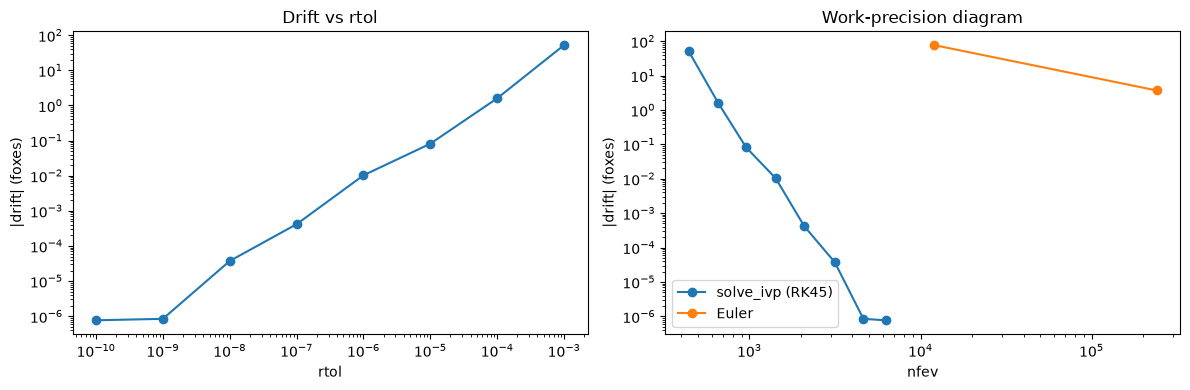

In [ ]:
rtols = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10]
drifts =[]
nfevs = []
peaks = []
for rtol in rtols:
    sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak, rtol=rtol, atol=1e-8)
    F_pk = sol.y_events[0][:, 1]
    drifts.append(F_pk[-1] - F_pk[0])
    nfevs.append(sol.nfev)
    peaks.append(F_pk)
    print(f"rtol = {rtol:.0e}   drift = {F_pk[-1]-F_pk[0]: .3e}   nfev = {sol.nfev:5d}   peaks = {np.round(F_pk, 6)}")

drifts = np.abs(drifts)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.loglog(rtols, drifts, "o-")
ax1.set_xlabel("rtol")
ax1.set_ylabel("|drift| (foxes)")
ax1.set_title("Drift vs rtol")
ax2.loglog(nfevs, drifts, "o-", label="solve_ivp (RK45)")  #sets the results on the log/log scale
ax2.loglog([12000, 240000], [77, 3.7], "o-", label="Euler") #sets the 
ax2.set_xlabel("nfev")
ax2.set_ylabel("|drift| (foxes)")
ax2.set_title("Work-precision diagram")
ax2.legend()
plt.tight_layout()
plt.show()

*Answer:*

a) rtol must be at least 1e-5 in order for the drift of foxes to be within 1 fox and 1e-7 to be within 0.01 of a fox.

b) The height of the fox peak is 2803.87010 +/- 0.000001.  This is because the two highest relative tolerances results in peaks with an approximately steady state drift.

c) From the relevant dataset, solv.ivp needs the number of steps associated with the first drift that is below 3.7.  This would be rtol = 1e-04, drift = 1.6, and nfev = 656

## 5. `atol`, and how few foxes is too few?

What is the **smallest** number of foxes during the cycle, and of rabbits? (Use
`dense_output=True` and a fine grid of times, or another event.)

Now someone argues: "A fraction of a fox is meaningless, so I'll set `atol = 1`."
Try it, with `rtol = 1e-6`. Then try `atol = 10`. What happens to the peaks? Explain
why, using the formula for the error tolerance, $\text{atol} + \text{rtol}\,|y|$.

And about the model itself: what does a population of under two foxes mean? Would a
real population survive that trough? (Lecture 10, kinetic Monte Carlo, is one way
to model that properly.)

In [30]:
solution = solve_ivp(dydt,(0,1200), y0, rtol = 1e-9, atol = 1e-8, dense_output= True)
time = np.linspace(0,1200,10000)
R, F = solution.sol(time)
print(f"minimum foxes   = {F.min():.3f}")
print(f"minimum rabbits = {R.min():.3f}")

# Effect of atol
for atol in [1e-8, 1, 10]:
    sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak, rtol=1e-6, atol=atol)
    print(f"atol = {atol:g}:  nfev = {sol.nfev:4d}   peaks = {np.round(s.y_events[0][:, 1], 2)}")

minimum foxes   = 1.594
minimum rabbits = 7.426
atol = 1e-08:  nfev = 1424   peaks = [2804.21 2593.16 2544.84 2315.84]
atol = 1:  nfev =  368   peaks = [2804.21 2593.16 2544.84 2315.84]
atol = 10:  nfev =  344   peaks = [2804.21 2593.16 2544.84 2315.84]


*Answer:*

## 6. Which method?

At `rtol = 1e-8, atol = 1e-8`, compare `method=` `"RK45"`, `"DOP853"`, `"LSODA"`,
`"BDF"` and `"Radau"`: drift and `nfev` for each. Which is cheapest for this
problem? Is this problem stiff? How can you tell?

*Answer:*

## Stretch problems

**(a)** For this system the quantity
$V = k_3 R - k_4 \ln R + k_2 F - k_1 \ln F$ stays exactly constant. (Differentiate
it and substitute the two ODEs to check.) That's why the orbit is closed. Plot
how much $V$ changes over 1200 days for a few values of `rtol`. Is it a better
measure of the error than the peak drift?

**(b)** Re-run with $k_3 = 0.00004$ day$^{-1}$ rabbits$^{-1}$ for 800 days, as in
Lecture 3. The fixed point moves from (100, 375) to (1000, 375). Do your
conclusions about `rtol` change?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.